<a href="https://colab.research.google.com/github/lshay33/Astrostatistics-Winter-2026-27/blob/main/L04_BAYESIAN_HUBBLE_DIAGRAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 04 — Bayesian Cosmology with a Real Pantheon+ Likelihood

**Format:** 4-hour hands-on practical  
**Status:** Formative + weekly checkpoint  
**Real data:** Pantheon+ / SH0ES  
**Covariance:** published statistical covariance

> ## Scientific question
> **How does a likelihood become a posterior, and how do nuisance calibration and prior choices propagate into cosmological uncertainty?**

We continue with the same real-data model:

$$
m_B^{\rm corr}
=
\mu(z;\Omega_m,H_0)+M_B+\epsilon,
$$

with \(H_0=70\) used only as a zero-point convention.

## 0. Five-line statement

**Estimand:** cosmological matter density parameter $\Omega_m$ and the absolute magnitude nuisance parameter $M_B$ (with $H_0 = 70 \text{ km s}^{-1}\text{Mpc}^{-1}$ used as a zero-point convention)

**Observed data:** corrected apparent magnitudes $m_B^{corr}$ and heliocentric redshifts $z_{HD}$ from the Pantheon+ / SH0ES dataset, restricted to non-Cepheid calibrators with $z_{HD} > 0.01$ and published statistical covariance matrices

**Generative assumptions:**  a flat $\Lambda$CDM universe ($T_{cmb0} = 2.725$ K) mapped via the distance modulus relation $\mu(z; \Omega_m, H_0)$, Gaussian distributed measurement errors represented by the covariance matrix $C_{stat}$, and uniform priors over the parameter grid   

**Uncertainty / selection:**  statistical measurement uncertainties from $C_{stat}$, propagation of covariance via Gaussian log-likelihoods ($\chi^2$), and data selection filtering out Cepheid calibrators and low-redshift sources ($z \le 0.01$)

**Validation / falsification test:** posterior predictive checks inspecting whether parameter sets supported by the posterior generate Hubble relations consistent with the observed data, and residual diagnostics across binned redshift intervals


In [1]:
from pathlib import Path
import io, sys, time, requests, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statistics as stat

from scipy.linalg import cho_factor, cho_solve
from scipy.interpolate import RegularGridInterpolator
from scipy.special import logsumexp
from astropy.cosmology import FlatLambdaCDM

SEED = 2026
rng = np.random.default_rng(SEED)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3


In [2]:
BASE = (
    "https://raw.githubusercontent.com/PantheonPlusSH0ES/"
    "DataRelease/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR/"
)
URL_DATA = BASE + "Pantheon%2BSH0ES.dat"
URL_STAT = BASE + "Pantheon%2BSH0ES_STATONLY.cov"
URL_FULL = BASE + "Pantheon%2BSH0ES_STAT%2BSYS.cov"

CACHE = Path("data_cache/pantheon_plus")
CACHE.mkdir(parents=True, exist_ok=True)

def download_if_needed(url, path, timeout=180):
    path = Path(path)
    if not path.exists():
        print("Downloading", path.name, "...")
        r = requests.get(url, timeout=timeout)
        r.raise_for_status()
        path.write_bytes(r.content)
    return path

def load_pantheon_table():
    p = download_if_needed(URL_DATA, CACHE/"Pantheon+SH0ES.dat")
    return pd.read_csv(p, sep=r"\s+")

def load_covariance(kind="STATONLY"):
    if kind.upper() == "STATONLY":
        url = URL_STAT
        path = CACHE/"Pantheon+SH0ES_STATONLY.cov"
    elif kind.upper() in {"FULL","STAT+SYS","STATSYS"}:
        url = URL_FULL
        path = CACHE/"Pantheon+SH0ES_STAT+SYS.cov"
    else:
        raise ValueError("kind must be STATONLY or FULL")

    p = download_if_needed(url, path)
    flat = np.loadtxt(p)
    n = int(flat[0])
    values = flat[1:]
    if values.size != n*n:
        raise ValueError(f"Expected {n*n} covariance entries, found {values.size}")
    return values.reshape(n, n)

sn = load_pantheon_table()
print("Pantheon+ rows:", len(sn))

Pantheon+ rows: 1701


In [3]:
def teaching_mask(sn):
    """Real-data teaching sample: non-Cepheid calibrators with zHD > 0.01."""
    mask = (
        np.isfinite(sn["zHD"].to_numpy(float)) &
        np.isfinite(sn["m_b_corr"].to_numpy(float)) &
        (sn["zHD"].to_numpy(float) > 0.01) &
        (sn["IS_CALIBRATOR"].to_numpy(int) == 0)
    )
    return mask

def subset_data_cov(sn, cov, mask):
    idx = np.flatnonzero(mask)
    d = sn.iloc[idx].reset_index(drop=True).copy()
    c = cov[np.ix_(idx, idx)]
    return d, c, idx

def mu_flat_lcdm(z, omega_m, H0=70.0):
    cosmo = FlatLambdaCDM(H0=H0, Om0=omega_m, Tcmb0=2.725)
    return cosmo.distmod(np.asarray(z, float)).value

def coefficient_grid(data, cov, omega_grid, H0=70.0):
    """
    For model m_b_corr = mu(z; Omega_m,H0) + M_B,
    compute coefficients so that
    chi2(Omega_m, M_B) = a - 2 M_B b + M_B^2 d.
    """
    z = data["zHD"].to_numpy(float)
    m = data["m_b_corr"].to_numpy(float)
    one = np.ones(len(data))

    cf = cho_factor(cov, lower=True, check_finite=False)
    cinv_one = cho_solve(cf, one, check_finite=False)
    dcoef = one @ cinv_one

    a = np.empty(len(omega_grid))
    b = np.empty(len(omega_grid))

    for k, om in enumerate(omega_grid):
        y = m - mu_flat_lcdm(z, om, H0=H0)
        cinv_y = cho_solve(cf, y, check_finite=False)
        a[k] = y @ cinv_y
        b[k] = one @ cinv_y

    return a, b, float(dcoef)

def profile_mb(a, b, d):
    mb_hat = b/d
    chi2_prof = a - b*b/d
    return mb_hat, chi2_prof

def chi2_surface(a, b, d, mb_grid):
    mb = np.asarray(mb_grid, float)[None, :]
    return a[:,None] - 2*b[:,None]*mb + d*mb*mb

In [4]:
cov_stat = load_covariance("STATONLY")
mask = teaching_mask(sn)
data, Cstat, original_indices = subset_data_cov(sn, cov_stat, mask)

OMEGA_GRID = np.linspace(0.10, 0.60, 101)
MB_GRID = np.linspace(-20.2, -18.2, 161)
H0_CONVENTION = 70.0

a, b, d = coefficient_grid(data, Cstat, OMEGA_GRID, H0=H0_CONVENTION)
CHI2 = chi2_surface(a, b, d, MB_GRID)

print("Posterior grid shape:", CHI2.shape)

Posterior grid shape: (101, 161)


# Part I — Bayes' theorem on a grid

## 1. Likelihood

Ignoring constants independent of ($\Omega_m,M_B$),

$$
\ln\mathcal L
=
-\frac12\chi^2.
$$

## 2. Baseline priors

Use

$$
p(\Omega_m)=\mathrm{Uniform}(0.10,0.60),
$$

$$
p(M_B)=\mathrm{Uniform}(-20.2,-18.2).
$$

Within those bounds, the prior is constant; outside it is zero.

Therefore the posterior shape inside the grid is simply proportional to the likelihood.

In [5]:
logL = -0.5 * CHI2

# Numerical normalization on the discrete grid.
logP = logL - logsumexp(logL)
P = np.exp(logP)
P /= P.sum()

print("Posterior grid normalization:", P.sum())

Posterior grid normalization: 1.0


## 3. Plot the joint posterior

Use posterior contours that enclose approximately 68% and 95% of the discrete posterior probability.

A contour at a fixed density value is not automatically a 68% contour; the density threshold must be chosen so that the enclosed probability has the desired value.

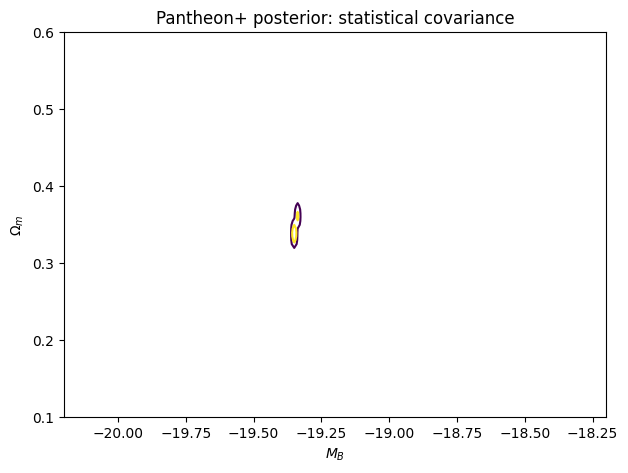

In [6]:
def density_thresholds(P, probs=(0.68,0.95)):
    flat = P.ravel()
    order = np.argsort(flat)[::-1]
    sorted_p = flat[order]
    csum = np.cumsum(sorted_p)
    thresholds = []
    for q in probs:
        j = np.searchsorted(csum, q)
        thresholds.append(sorted_p[j])
    return thresholds

thr68, thr95 = density_thresholds(P, (0.68,0.95))

fig, ax = plt.subplots(figsize=(7,5))
# contour levels must be increasing:
ax.contour(MB_GRID, OMEGA_GRID, P, levels=sorted([thr95,thr68]))
ax.set_xlabel(r"$M_B$")
ax.set_ylabel(r"$\Omega_m$")
ax.set_title("Pantheon+ posterior: statistical covariance")
plt.show()

### Exercise 1

Describe the orientation of the $(\Omega_m,M_B)$ posterior.

Is it strongly degenerate, weakly correlated, or nearly separable over this redshift range?

Do not infer this from a correlation coefficient alone—look at the geometry.


> The orientation of the $(\Omega_m,M_B)$ posterior is a nearly vertical diagonal covariance, exhibiting a strong negative correlation where higher values of $\Omega_m$ corresponds to lower values of $M_B$.
>
>It is strongly degenerate over this redshift range because the simultaneous changes in $\Omega_m$ and $M_B$ shift the distance modulus curve in a way that compensates across the observed magnitude range.

# Part II — Marginalization

## 4. Marginal posteriors

For the discrete grid,

$$
p(\Omega_m\mid D)
\propto
\sum_{M_B}
p(\Omega_m,M_B\mid D),
$$

and similarly for $M_B$.

Omega_m 16/50/84: [[np.float64(0.3301049010057788), np.float64(0.34128749687986115), np.float64(0.3592152335482662)]]
M_B     16/50/84: [[np.float64(-19.35965914392514), np.float64(-19.353245894989964), np.float64(-19.343574768446004)]]


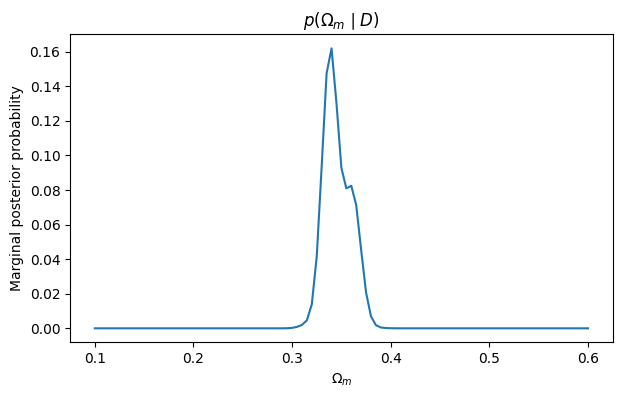

The posterior mode in Omega_m is:  0.3301049010057788


In [7]:
p_om = P.sum(axis=1)
p_mb = P.sum(axis=0)

p_om /= p_om.sum()
p_mb /= p_mb.sum()

def discrete_quantile(grid, p, q):
    c = np.cumsum(p)
    return np.interp(q, c, grid)

om_q = [discrete_quantile(OMEGA_GRID,p_om,q) for q in (0.16,0.50,0.84)]
mb_q = [discrete_quantile(MB_GRID,p_mb,q) for q in (0.16,0.50,0.84)]

print("Omega_m 16/50/84:", [om_q])
print("M_B     16/50/84:", [mb_q])

fig, ax = plt.subplots(figsize=(7,4))
ax.plot(OMEGA_GRID, p_om)
ax.set_xlabel(r"$\Omega_m$")
ax.set_ylabel("Marginal posterior probability")
ax.set_title(r"$p(\Omega_m\mid D)$")
plt.show()

single_mode = stat.mode(om_q)
print("The posterior mode in Omega_m is: ", single_mode)

### Exercise 2

Report the posterior median and central 68% credible interval for both parameters.

>The posterior median for $\Omega_m$ is 0.341287 with a 68% CI of [0.330105,0.359215].
>The posterior median for $M_B$ is -19.353246 with a 68% CI of [-19.359659,-19.343575].

Then compare the posterior mode in $(\Omega_m)$ with the profile-likelihood MLE from Lab 03.

The posterior mode is $(\Omega_m)$=0.330104 where the profile-likelihood MLE from Lab 3 is $(\Omega_m)$=0.345.

Explain why they need not be numerically identical.

These do not need to be identical because when profiling for every fixed $\Omega_m$, we choose the value of $M_B$ that maximizes the likelihood, therefore keeps only one nuisance value at each$\Omega_m$. When we use posterior prediction models (and marginalization), the process removes a nuisance paramter by integration, and therefore keeps the contribution of all nuisance-parameter values.

# Part III — Prior sensitivity

## 5. A deliberately informative alternative prior

To learn what prior sensitivity looks like, apply

$$
\Omega_m\sim\mathcal N(0.30,0.03^2)
$$

truncated to the grid.

This is a **teaching prior**, not a claim that this is the correct external prior to use in a publication.

Omega_m 16/50/84: [[np.float64(0.3257153546504236), np.float64(0.3346685589715621), np.float64(0.34599409785083707)]]
M_B     16/50/84: [[np.float64(-19.360472917548904), np.float64(-19.355458227096737), np.float64(-19.350443536644573)]]


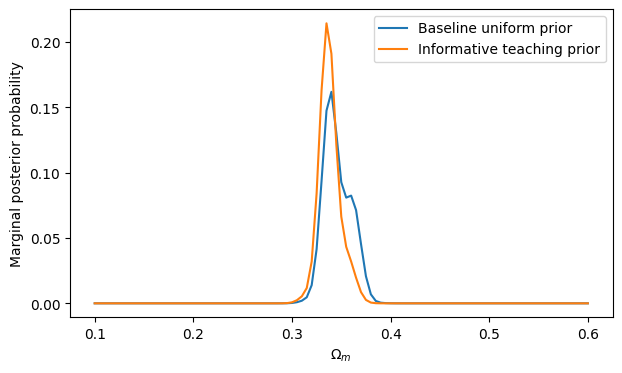

In [8]:
prior_om_alt = np.exp(-0.5*((OMEGA_GRID-0.30)/0.03)**2)
prior_om_alt /= prior_om_alt.sum()

log_prior2d = np.log(prior_om_alt[:,None] + 1e-300)
logP_alt = logL + log_prior2d
logP_alt -= logsumexp(logP_alt)
P_alt = np.exp(logP_alt)
P_alt /= P_alt.sum()

p_om_alt = P_alt.sum(axis=1)
p_om_alt /= p_om_alt.sum()

p_mb_alt = P_alt.sum(axis=0)
p_mb_alt /= p_mb_alt.sum()

def discrete_quantile(grid, p, q):
    c = np.cumsum(p)
    return np.interp(q, c, grid)

om_q_alt = [discrete_quantile(OMEGA_GRID,p_om_alt,q) for q in (0.16,0.50,0.84)]
mb_q_alt = [discrete_quantile(MB_GRID,p_mb_alt,q) for q in (0.16,0.50,0.84)]

print("Omega_m 16/50/84:", [om_q_alt])
print("M_B     16/50/84:", [mb_q_alt])

fig, ax = plt.subplots(figsize=(7,4))
ax.plot(OMEGA_GRID, p_om, label="Baseline uniform prior")
ax.plot(OMEGA_GRID, p_om_alt, label="Informative teaching prior")
ax.set_xlabel(r"$\Omega_m$")
ax.set_ylabel("Marginal posterior probability")
ax.legend()
plt.show()

### Exercise 3

Calculate the 16th/50th/84th percentiles under the alternative prior.

>For $\Omega_m$, the 16th/50th/84th percentiles under the alternative prior are [0.325715,0.334669,0.345994].
>
>For $M_B$, the 16th/50th/84th percentiles under the alternative prior are [-19.360473, -19.355458, -19.350444].

>The posterior median for $\Omega_m$ is 0.341287 with a 68% CI of [0.330105,0.359215].
>The posterior median for $M_B$ is -19.353246 with a 68% CI of [-19.359659,-19.343575].

Then answer:

1. Did the posterior location change?
> Yes, the posterior location changed as it was pulled closer to the mean of the informative prior.
2. Did its width change?
> Yes, the width became more narrow such that the informatice prior adds an external constraint.
3. Is the data likelihood strong enough to overwhelm this prior?
> The prior strongly shapes the final posterior. Having a tight informative prior then significantly reduces the paramater space.
4. Why is “the posterior is objective” an incorrect statement?
> The posterior is mathematically conditional on both the observed data and the chosen prior distributions and generative model assumptions.

# Part IV — Posterior predictive thinking

## 6. Draw parameter pairs from the grid posterior

A posterior predictive check asks whether parameter values supported by the posterior generate predictions that resemble the observed data in relevant ways.

For this lab, draw posterior parameter pairs and calculate residual curves. We are **not** generating synthetic supernovae.

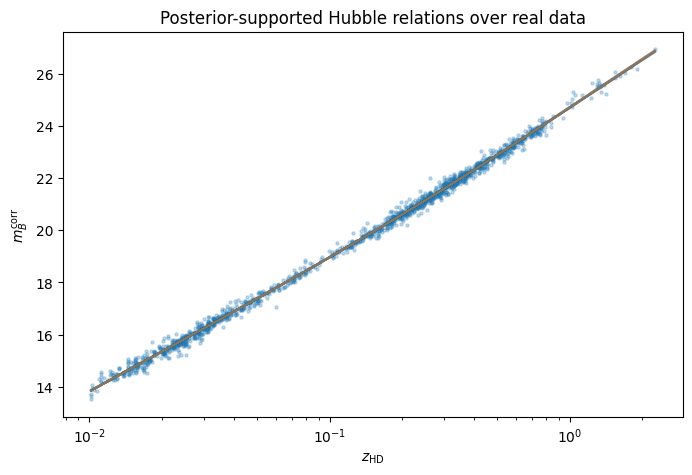

In [9]:
n_draw = 100
flat_idx = rng.choice(P.size, size=n_draw, replace=True, p=P.ravel())
io, im = np.unravel_index(flat_idx, P.shape)

z_plot = np.geomspace(max(0.01,data["zHD"].min()), data["zHD"].max(), 250)

fig, ax = plt.subplots(figsize=(8,5))
for k in range(n_draw):
    om = OMEGA_GRID[io[k]]
    mb = MB_GRID[im[k]]
    m_pred = mu_flat_lcdm(z_plot, om, H0=H0_CONVENTION) + mb
    ax.plot(z_plot, m_pred, alpha=0.05)

ax.scatter(data["zHD"], data["m_b_corr"], s=5, alpha=0.25)
ax.set_xscale("log")
ax.set_xlabel(r"$z_{\rm HD}$")
ax.set_ylabel(r"$m_B^{\rm corr}$")
ax.set_title("Posterior-supported Hubble relations over real data")
plt.show()

### Exercise 4 — residual diagnostic

Using the posterior median parameters:

1. calculate magnitude residuals;
2. bin them only for visualization in 6–10 redshift bins;
3. plot median residual per bin with a bootstrap uncertainty on that median.

State clearly that these bins are a visualization diagnostic, not independent measurements used in the likelihood.

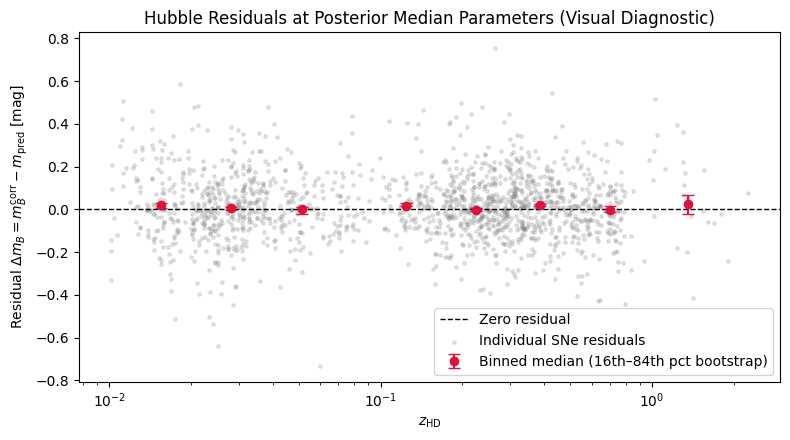

In [12]:
#bin the residuals into 6 to 10 redshift bins solely for visual purposes
#plot the median residual per bin accompanies by the bootstrap uncertainty bars on that median

# Extract posterior median parameters from baseline uniform prior
om_med = om_q[1]
mb_med = mb_q[1]

# Calculate magnitude residuals: r = m_B^corr - m_pred(z; Omega_m_med, M_B_med)
z_data = data["zHD"].to_numpy(float)
m_data = data["m_b_corr"].to_numpy(float)
m_pred_med = mu_flat_lcdm(z_data, om_med, H0=H0_CONVENTION) + mb_med
res = m_data - m_pred_med

# Bin into 8 log-spaced redshift bins (strictly for visual inspection)
n_bins = 8
bin_edges = np.geomspace(z_data.min(), z_data.max(), n_bins + 1)

bin_centers = []
bin_medians = []
err_low = []
err_high = []

n_boot = 2000

for i in range(n_bins):
    # Include right endpoint on the final bin
    if i < n_bins - 1:
        in_bin = (z_data >= bin_edges[i]) & (z_data < bin_edges[i + 1])
    else:
        in_bin = (z_data >= bin_edges[i]) & (z_data <= bin_edges[i + 1])

    r_bin = res[in_bin]
    z_bin = z_data[in_bin]

    med = np.median(r_bin)

    # Bootstrap resampling for uncertainty on the bin median
    boot_samples = rng.choice(r_bin, size=(n_boot, len(r_bin)), replace=True)
    boot_medians = np.median(boot_samples, axis=1)
    q16, q84 = np.percentile(boot_medians, [16, 84])

    bin_centers.append(np.median(z_bin))
    bin_medians.append(med)
    err_low.append(med - q16)
    err_high.append(q84 - med)

# Plot unbinned residuals alongside binned medians with bootstrap error bars
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axhline(0.0, color="black", linestyle="--", linewidth=1, label="Zero residual")
ax.scatter(z_data, res, s=6, alpha=0.2, color="gray", label="Individual SNe residuals")
ax.errorbar(
    bin_centers,
    bin_medians,
    yerr=[err_low, err_high],
    fmt="o",
    color="crimson",
    ecolor="crimson",
    capsize=4,
    linewidth=1.5,
    label="Binned median (16th–84th pct bootstrap)"
)

ax.set_xscale("log")
ax.set_xlabel(r"$z_{\rm HD}$")
ax.set_ylabel(r"Residual $\Delta m_B = m_B^{\rm corr} - m_{\rm pred}$ [mag]")
ax.set_title("Hubble Residuals at Posterior Median Parameters (Visual Diagnostic)")
ax.legend()
plt.tight_layout()
plt.show()


# 7. In-class checkpoint

Show:

1. normalized 2-D posterior;
2. 68% and 95% contours;
3. marginal (p(\Omega_m\mid D)\);
4. 68% credible intervals;
5. prior-sensitivity comparison;
6. one posterior-supported Hubble-diagram visualization.

### Exit question

> Which statements in this lab are properties of the data, and which are conditional on the prior and model?
>
>Properties of the data include the measured apparent magnitudes, heliocentric redshifts, and the published statistical covariance matrix. Conditional properties on the prior and model include the joint posterior distribution, marginal credible intervals, paramter location shifts, and distance modulus theoretical curves.

# 8. Bridge to Lab 05

In two dimensions, a grid is powerful because we can directly inspect and normalize the posterior.

Next week we deliberately introduce MCMC and ask:

- Can a sampler reproduce the known grid posterior?
- How do we diagnose convergence?
- What changes when systematic covariance is added?
- Why should we not use MCMC merely because it is fashionable?